# 06. Biến Đổi Hilbert-Huang (HHT): Tần Số Tức Thời & Phổ Năng Lượng Hilbert
### Hilbert-Huang Transform (HHT): Instantaneous Frequency & Hilbert Spectrum
**Tác giả:** Antigravity AI Assistant & Biomedical Signal DSP Specialist  
**Mục tiêu:**
1. Hoàn thiện quy trình HHT: **CEEMDAN Decomposition + Hilbert Spectral Analysis (HSA)**.
2. Xây dựng tín hiệu giải tích (*Analytic Signal*), tính toán Biên độ tức thời $a(t)$ và Tần số tức thời $f(t) = rac{1}{2\pi}rac{d	heta}{dt}$.
3. Trực quan hóa **Phổ Hilbert 2D $H(\omega, t)$** và **Phổ cận biên Hilbert (Marginal Hilbert Spectrum)** so với phổ Fourier truyền thống.


In [1]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
from PyEMD import CEEMDAN

plt.style.use('default')
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 10,
    'axes.labelsize': 10,
    'axes.titlesize': 11,
    'axes.titleweight': 'bold',
    'figure.dpi': 130
})

DATA_PATH = r"e:\Study\S1\S1.pkl"
with open(DATA_PATH, "rb") as f:
    s1_data = pickle.load(f, encoding="latin1")

bvp_raw = s1_data['signal']['wrist']['BVP'].flatten()
fs_bvp = 64.0

# Trích đoạn tín hiệu PPG 10 giây
t_start = 120.0
win_sec = 10.0
N_win = int(win_sec * fs_bvp)

bvp_seg = bvp_raw[int(t_start*fs_bvp):int(t_start*fs_bvp) + N_win]
t_rel = np.arange(N_win) / fs_bvp

# Chạy phân rã CEEMDAN
ceemdan = CEEMDAN(trials=20, epsilon=0.2, parallel=False)
imfs = ceemdan(bvp_seg, t_rel)
num_imfs = imfs.shape[0]

print(f"Đã phân rã CEEMDAN thành {num_imfs} IMFs.")


Đã phân rã CEEMDAN thành 8 IMFs.


## 1. Biến Đổi Hilbert & Tính Toán Tần Số Tức Thời
Với mỗi IMF $c_k(t)$, ta tạo tín hiệu giải tích phức:
$$z_k(t) = c_k(t) + j 	ilde{c}_k(t) = a_k(t) e^{j 	heta_k(t)}$$
Tần số tức thời (Hz):
$$f_k(t) = rac{1}{2\pi} rac{d	heta_k(t)}{dt}$$


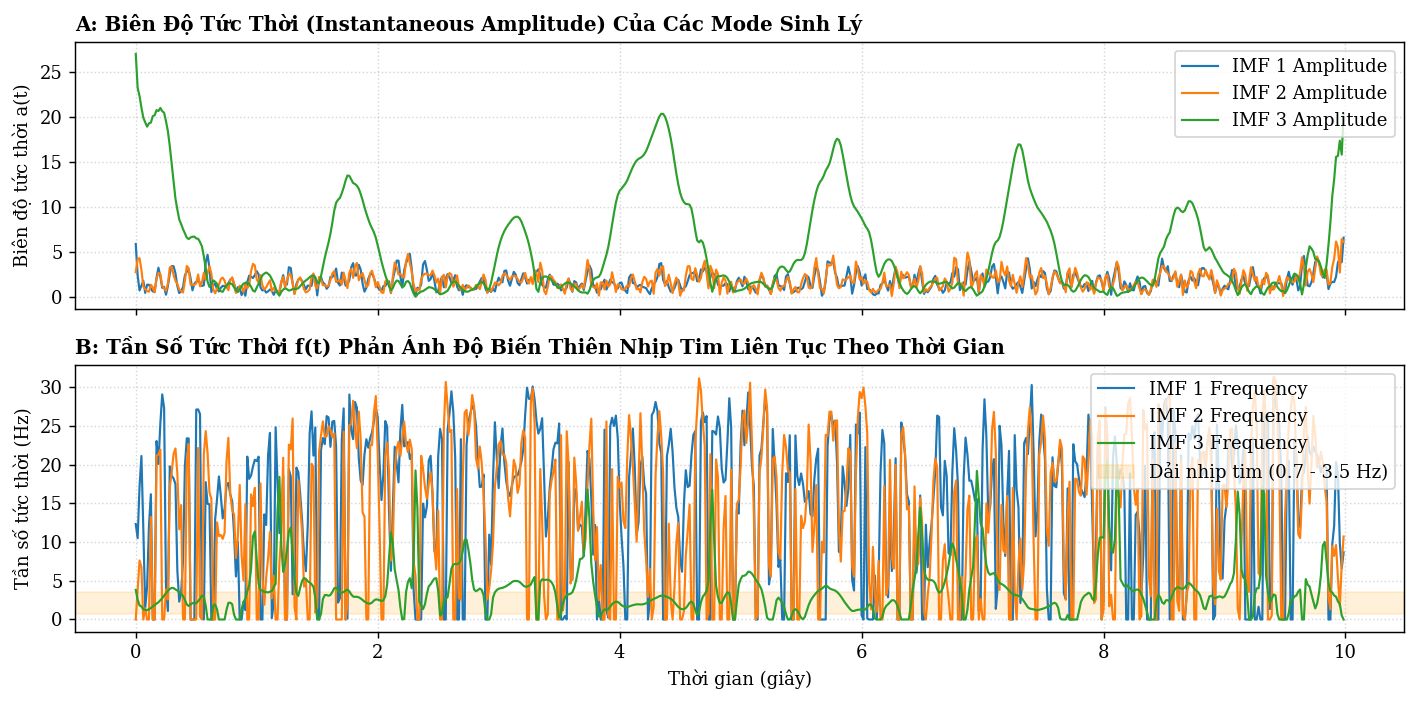

In [2]:
inst_amps = []
inst_freqs = []

for k in range(num_imfs - 1): # Bỏ qua residue cuối
    imf = imfs[k]
    # Biến đổi Hilbert
    analytic = signal.hilbert(imf)
    amp = np.abs(analytic)
    phase = np.unwrap(np.angle(analytic))
    # Tần số tức thời qua đạo hàm pha
    freq = (np.gradient(phase) / (2.0 * np.pi)) * fs_bvp
    
    # Giới hạn vật lý để biểu diễn sạch
    freq = np.clip(freq, 0, fs_bvp / 2.0)
    
    inst_amps.append(amp)
    inst_freqs.append(freq)

# Vẽ quỹ đạo tần số tức thời của 3 IMF đầu
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)

for k in range(min(3, len(inst_freqs))):
    ax1.plot(t_rel, inst_amps[k], label=f'IMF {k+1} Amplitude', lw=1.2)
ax1.set_ylabel('Biên độ tức thời a(t)')
ax1.set_title('A: Biên Độ Tức Thời (Instantaneous Amplitude) Của Các Mode Sinh Lý', loc='left')
ax1.legend(loc='upper right')
ax1.grid(True, linestyle=':', alpha=0.5)

for k in range(min(3, len(inst_freqs))):
    ax2.plot(t_rel, inst_freqs[k], label=f'IMF {k+1} Frequency', lw=1.2)
ax2.axhspan(0.7, 3.5, color='orange', alpha=0.15, label='Dải nhịp tim (0.7 - 3.5 Hz)')
ax2.set_ylabel('Tần số tức thời (Hz)')
ax2.set_xlabel('Thời gian (giây)')
ax2.set_title('B: Tần Số Tức Thời f(t) Phản Ánh Độ Biến Thiên Nhịp Tim Liên Tục Theo Thời Gian', loc='left')
ax2.legend(loc='upper right')
ax2.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()


## 2. Phổ Năng Lượng Hilbert 2D $H(\omega, t)$ và Phổ Cận Biên
Xây dựng biểu đồ phân bố năng lượng theo thời gian và tần số tức thời, sau đó tích phân theo thời gian để thu được Phổ Cận Biên Hilbert (Marginal Hilbert Spectrum) so sánh với FFT.


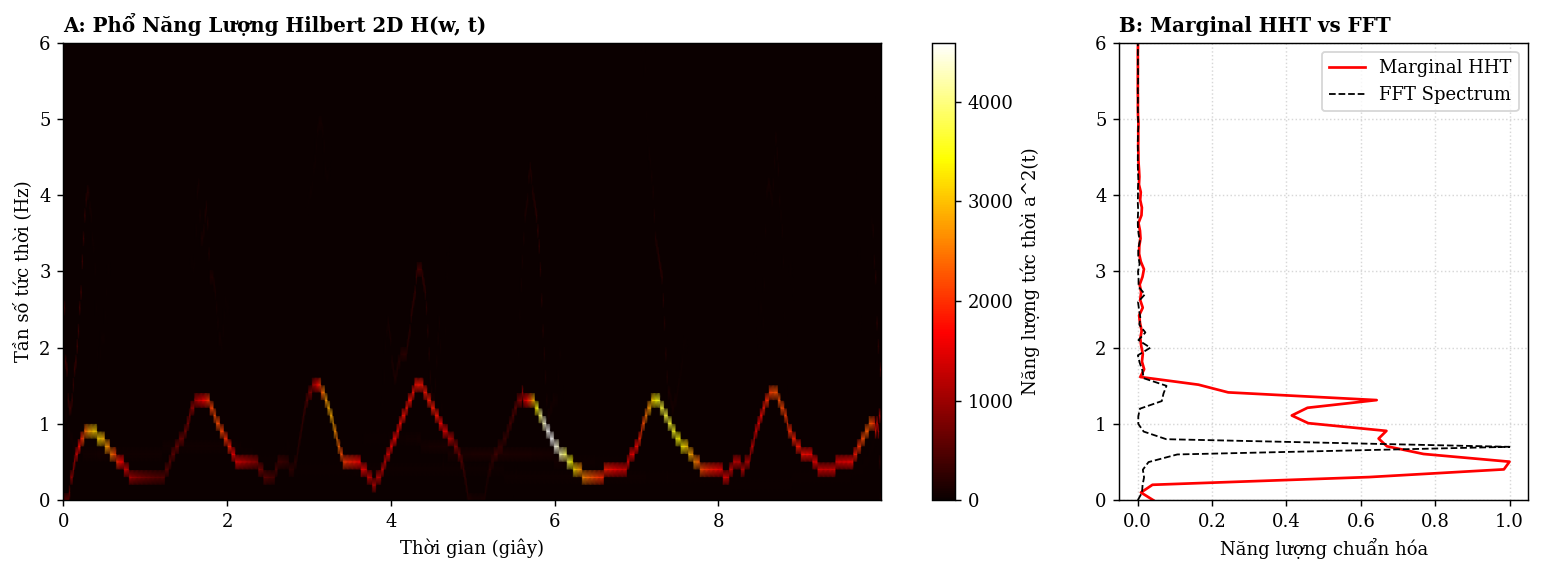

=> Phổ Hilbert cho độ phân giải tần số tức thời sắc nét, không bị giới hạn bởi độ rộng cửa sổ như STFT!


In [3]:
# Xây dựng lưới phổ Hilbert
freq_bins = np.linspace(0, 10.0, 100)
time_bins = t_rel
H_matrix = np.zeros((len(freq_bins), len(time_bins)))

for k in range(len(inst_freqs)):
    f_k = inst_freqs[k]
    a_k = inst_amps[k]
    for t_idx in range(len(time_bins)):
        f_val = f_k[t_idx]
        if f_val < 10.0:
            bin_idx = np.argmin(np.abs(freq_bins - f_val))
            H_matrix[bin_idx, t_idx] += a_k[t_idx]**2

# Phổ cận biên Hilbert: h(w) = tích phân H(w, t) dt
marginal_hht = np.sum(H_matrix, axis=1)

# Phổ FFT tương ứng để so sánh
fft_vals = np.fft.rfft(bvp_seg - np.mean(bvp_seg))
fft_freqs = np.fft.rfftfreq(len(bvp_seg), d=1.0/fs_bvp)
fft_psd = np.abs(fft_vals)**2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={'width_ratios': [2.5, 1]})

# Đồ thị 1: Hilbert Spectrum Heatmap
pcm = ax1.pcolormesh(time_bins, freq_bins, H_matrix, shading='gouraud', cmap='hot')
ax1.set_ylim([0, 6.0])
ax1.set_xlabel('Thời gian (giây)')
ax1.set_ylabel('Tần số tức thời (Hz)')
ax1.set_title('A: Phổ Năng Lượng Hilbert 2D H(w, t)', loc='left')
fig.colorbar(pcm, ax=ax1, label='Năng lượng tức thời a^2(t)')

# Đồ thị 2: Phổ cận biên HHT vs Phổ FFT
ax2.plot(marginal_hht / np.max(marginal_hht), freq_bins, 'r-', lw=1.5, label='Marginal HHT')
mask_fft = fft_freqs <= 6.0
ax2.plot(fft_psd[mask_fft] / np.max(fft_psd[mask_fft]), fft_freqs[mask_fft], 'k--', lw=1.0, label='FFT Spectrum')
ax2.set_ylim([0, 6.0])
ax2.set_xlabel('Năng lượng chuẩn hóa')
ax2.set_title('B: Marginal HHT vs FFT', loc='left')
ax2.legend(loc='upper right')
ax2.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

print("=> Phổ Hilbert cho độ phân giải tần số tức thời sắc nét, không bị giới hạn bởi độ rộng cửa sổ như STFT!")


## Kết Luận Notebook 6:
- HHT cung cấp cái nhìn thực sự phi tuyến và phi dừng cho tín hiệu y sinh.
- Phổ Hilbert biểu diễn chính xác thời điểm và tần số thực sự của các quá trình huyết động học mà các phương pháp truyền thống (FFT/STFT) không thể nắm bắt trọn vẹn.
